In [1]:
import sklearn

In [2]:
# create data
from sklearn.datasets import make_circles

n_samples = 1000

X, y = make_circles(n_samples, noise=0.03, random_state=42)

In [3]:
X[:5] #2 feature of x to predict 1 label of y

array([[ 0.75424625,  0.23148074],
       [-0.75615888,  0.15325888],
       [-0.81539193,  0.17328203],
       [-0.39373073,  0.69288277],
       [ 0.44220765, -0.89672343]])

In [4]:
y[:5] #binary classification

array([1, 1, 1, 1, 0])

In [5]:
len(X), len(y)

(1000, 1000)

In [6]:
import pandas as pd
circles = pd.DataFrame({"X1" : X[:, 0],
                        "X2" : X[:, 1],
                        "label" : y})

circles #it's hard to know the pattern between X and y

,X1,X2,label
0,0.754246,0.231481,1
1,-0.756159,0.153259,1
2,-0.815392,0.173282,1
3,-0.393731,0.692883,1
4,0.442208,-0.896723,0
...,...,...,...
995,0.244054,0.944125,0
996,-0.978655,-0.272373,0
997,-0.136900,-0.810012,1
998,0.670362,-0.767502,0


In [7]:
circles.label.value_counts()

label
1    500
0    500
Name: count, dtype: int64

In [8]:
X[0,0]

0.7542462506997276

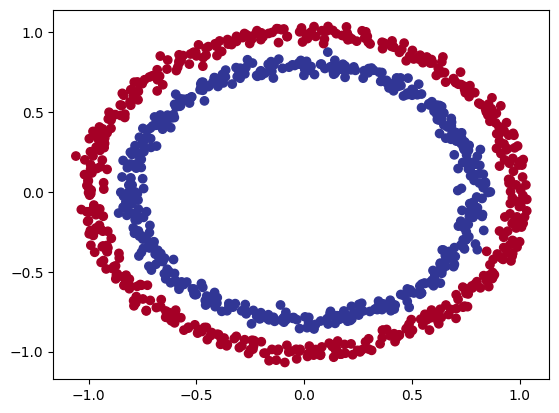

In [9]:
import matplotlib.pyplot as plt
plt.scatter(x=circles["X1"], #or x=X[:, 0]
            y=circles["X2"], #or y=X[:, 1]
            c=circles["label"], #or c=y
            cmap=plt.cm.RdYlBu)

In [10]:
X.shape, y.shape

((1000, 2), (1000,))

In [11]:
X.dtype

dtype('float64')

In [12]:
X_sample = X[0]
y_sample = y[0]

X_sample, y_sample

(array([0.75424625, 0.23148074]), 1)

In [13]:
type(X)

numpy.ndarray

In [14]:
X_sample.shape, y_sample.shape

((2,), ())

In [15]:
type(X), type(y) #numpy array

(numpy.ndarray, numpy.ndarray)

In [16]:
X[:5], y[:5]

(array([[ 0.75424625,  0.23148074],
        [-0.75615888,  0.15325888],
        [-0.81539193,  0.17328203],
        [-0.39373073,  0.69288277],
        [ 0.44220765, -0.89672343]]),
 array([1, 1, 1, 1, 0]))

In [17]:
#turn data into tensors
import torch
X = torch.from_numpy(X).type(torch.float32)
y = torch.from_numpy(y).type(torch.float32)

In [18]:
type(X), type(y)

(torch.Tensor, torch.Tensor)

In [19]:
X[:5], y[:5]

(tensor([[ 0.7542,  0.2315],
         [-0.7562,  0.1533],
         [-0.8154,  0.1733],
         [-0.3937,  0.6929],
         [ 0.4422, -0.8967]]),
 tensor([1., 1., 1., 1., 0.]))

In [20]:
torch.manual_seed(42)

In [21]:
#splitting data 
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test =train_test_split(X, y, test_size=0.2, random_state=42) 

In [22]:
len(X_train), len(X_test)

(800, 200)

In [23]:
len(y_train), len(y_test)

(800, 200)

In [24]:
n_samples

1000

In [25]:
import torch
from torch import nn

class circleModelV0(nn.Module):
    def __init__(self):
        super().__init__()
        self.layer1 = nn.Linear(in_features=2, out_features=5)
        self.layer2 = nn.Linear(in_features=5, out_features=1)
        
    def forward(self, X):
        return self.layer2(self.layer1(X)) #X --> layer1 --> layer2 -->output

In [26]:
#instantiate an instance
model_1 = circleModelV0()
model_1

circleModelV0(
  (layer1): Linear(in_features=2, out_features=5, bias=True)
  (layer2): Linear(in_features=5, out_features=1, bias=True)
)

In [27]:
#other way and the better way
model_1 = nn.Sequential(nn.Linear(in_features=2, out_features=5),
                        nn.Linear(in_features=5, out_features=1))  #بيمرر المدخلات على الطبقة الأولى، ونتيجة الأولى على الثانية، بالترتيب اللي حددته دون الحاجة لكتابته يدوياً
model_1 #override

Sequential(
  (0): Linear(in_features=2, out_features=5, bias=True)
  (1): Linear(in_features=5, out_features=1, bias=True)
)

In [28]:
model_1.state_dict()

OrderedDict([('0.weight',
              tensor([[-0.0829, -0.2872],
                      [ 0.4691, -0.5582],
                      [-0.3260, -0.1997],
                      [-0.4252,  0.0667],
                      [-0.6984,  0.6386]])),
             ('0.bias', tensor([-0.6007,  0.5459,  0.1177, -0.2296,  0.4370])),
             ('1.weight',
              tensor([[ 0.0697,  0.3613,  0.0489, -0.1410,  0.1202]])),
             ('1.bias', tensor([-0.1213]))])

In [29]:
list(model_1.parameters())

[Parameter containing:
 tensor([[-0.0829, -0.2872],
         [ 0.4691, -0.5582],
         [-0.3260, -0.1997],
         [-0.4252,  0.0667],
         [-0.6984,  0.6386]], requires_grad=True),
 Parameter containing:
 tensor([-0.6007,  0.5459,  0.1177, -0.2296,  0.4370], requires_grad=True),
 Parameter containing:
 tensor([[ 0.0697,  0.3613,  0.0489, -0.1410,  0.1202]], requires_grad=True),
 Parameter containing:
 tensor([-0.1213], requires_grad=True)]

In [30]:
# Make predictions
with torch.inference_mode():
    untrained_preds = model_1(X_test)
print(f"Length of predictions: {len(untrained_preds)}, Shape: {untrained_preds.shape}")
print(f"Length of test samples: {len(X_test)}, Shape: {X_test.shape}")
print(f"\nFirst 10 predictions:\n{untrained_preds[:10]}")
print(f"\nFirst 10 labels:\n{y_test[:10].unsqueeze(dim=1)}")

Length of predictions: 200, Shape: torch.Size([200, 1])
Length of test samples: 200, Shape: torch.Size([200, 2])

First 10 predictions:
tensor([[-0.0338],
        [-0.0309],
        [ 0.0894],
        [-0.0692],
        [ 0.2967],
        [ 0.2968],
        [ 0.1405],
        [ 0.2178],
        [ 0.0805],
        [-0.0284]])

First 10 labels:
tensor([[1.],
        [0.],
        [1.],
        [0.],
        [1.],
        [1.],
        [0.],
        [0.],
        [1.],
        [0.]])


In [31]:
#set up loss function and optimizer
#loss_fn = BCELoss() #requires inputs to have gone through the sigmoid activation function prior to input to BCELoss
loss_fn = nn.BCEWithLogitsLoss() #BCEWithLogitsLoss --> sigmoid activation function built-in + numerical stability

optimizer = torch.optim.SGD(params=model_1.parameters(),
                            lr=0.1)

/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [32]:
model_1.state_dict() #all of these values will be updated by the optimizer

OrderedDict([('0.weight',
              tensor([[-0.0829, -0.2872],
                      [ 0.4691, -0.5582],
                      [-0.3260, -0.1997],
                      [-0.4252,  0.0667],
                      [-0.6984,  0.6386]])),
             ('0.bias', tensor([-0.6007,  0.5459,  0.1177, -0.2296,  0.4370])),
             ('1.weight',
              tensor([[ 0.0697,  0.3613,  0.0489, -0.1410,  0.1202]])),
             ('1.bias', tensor([-0.1213]))])

In [33]:
#calculate accuracy((TP + TN) / (TP + TN + FP + FN)) * 100  من بين كل مية عينة كم المودل تبعنا جاب صح

def accuracy(y_true, y_pred):
    correct = torch.eq(y_true, y_pred).sum().item()
    acc = (correct / len(y_pred))*100
    return acc

### raw logits ---> pred_prob ---> pred_labels

In [34]:
model_1.eval()
with torch.inference_mode():
    y_logits = model_1(X_test)
y_logits[:5] #raw logits

tensor([[-0.0338],
        [-0.0309],
        [ 0.0894],
        [-0.0692],
        [ 0.2967]])

In [35]:
y_test[:5]

tensor([1., 0., 1., 0., 1.])

In [36]:
#use sigmoid activation function to turn them into prediction probabilities values
y_preds_prob = torch.sigmoid(y_logits)
y_preds_prob[:5]

tensor([[0.4916],
        [0.4923],
        [0.5223],
        [0.4827],
        [0.5736]])

In [37]:
y_preds = torch.round(y_preds_prob)[:5] # same format as y_test but not the same values because our model is used a random weight to make predictions
y_preds

tensor([[0.],
        [0.],
        [1.],
        [0.],
        [1.]])

In [38]:
#in full 
y_preds_labels = torch.round(torch.sigmoid(model_1(X_test)[:5]))
y_preds_labels

tensor([[0.],
        [0.],
        [1.],
        [0.],
        [1.]], grad_fn=<RoundBackward0>)

In [39]:
#هل الطريقتين اعطو نفس النتيجة؟
print(torch.eq(y_preds.squeeze(), y_preds_labels.squeeze()))

tensor([True, True, True, True, True])


In [40]:
#training loop

torch.manual_seed(42)
epochs = 100

for epoch in range(epochs):
    model_1.train()
    
    y_logits = model_1(X_train).squeeze()
    y_pred = torch.round(torch.sigmoid(y_logits))
    
    #loss and accuracy  acc مش ضروري بس لانو عرفناها فوق
    loss = loss_fn(y_logits, #nn.BCEWithLogitsLoss() expect raw logits as input and this is the difference between nn.BCEWithLogitsLoss() and nn.BCELoss()
                   y_train) 
    acc = accuracy(y_true=y_train, y_pred=y_pred)
    
    optimizer.zero_grad()
    
    loss.backward()
    optimizer.step()
    
    #testing loop
    model_1.eval()
    with torch.inference_mode():
        test_logits = model_1(X_test).squeeze() #test_logits is the raw output of our model with no modifications
        test_pred = torch.round(torch.sigmoid(test_logits))
         
        test_loss = loss_fn(test_logits, y_test)
        test_acc = accuracy(y_true=y_test, y_pred=test_pred)
        
    if epoch % 10 ==0 :
            print(f"Epoch: {epoch} | Loss: {loss:.5f} | Acc:{acc:.2f}% | Test Loss: {test_loss:.5f} | Test_Acc:{test_acc:.2f}%") 
    
    

Epoch: 0 | Loss: 0.69796 | Acc:51.88% | Test Loss: 0.69440 | Test_Acc:58.00%
Epoch: 10 | Loss: 0.69590 | Acc:51.25% | Test Loss: 0.69305 | Test_Acc:53.00%
Epoch: 20 | Loss: 0.69490 | Acc:51.62% | Test Loss: 0.69254 | Test_Acc:49.50%
Epoch: 30 | Loss: 0.69435 | Acc:51.12% | Test Loss: 0.69236 | Test_Acc:49.50%
Epoch: 40 | Loss: 0.69401 | Acc:50.88% | Test Loss: 0.69232 | Test_Acc:51.00%
Epoch: 50 | Loss: 0.69378 | Acc:50.25% | Test Loss: 0.69234 | Test_Acc:50.00%
Epoch: 60 | Loss: 0.69362 | Acc:50.00% | Test Loss: 0.69239 | Test_Acc:51.50%
Epoch: 70 | Loss: 0.69351 | Acc:50.25% | Test Loss: 0.69246 | Test_Acc:51.00%
Epoch: 80 | Loss: 0.69342 | Acc:49.88% | Test Loss: 0.69254 | Test_Acc:50.00%
Epoch: 90 | Loss: 0.69336 | Acc:49.88% | Test Loss: 0.69262 | Test_Acc:53.00%


In [41]:
loss_fn

BCEWithLogitsLoss()

In [42]:
import numpy as np

In [43]:
def plot_decision_boundary(model: torch.nn.Module, X: torch.Tensor, y: torch.Tensor, ax=None):
    if ax is None:
        ax = plt.gca()
        
    model.to("cpu")
    X, y = X.to("cpu"), y.to("cpu")

    x_min, x_max = X[:, 0].min() - 0.1, X[:, 0].max() + 0.1
    y_min, y_max = X[:, 1].min() - 0.1, X[:, 1].max() + 0.1
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 101),
                         np.linspace(y_min, y_max, 101))

    X_to_pred_on = torch.from_numpy(np.column_stack((xx.ravel(), yy.ravel()))).float()

    model.eval()
    with torch.inference_mode():
        y_logits = model(X_to_pred_on)

    if len(torch.unique(y)) > 2:
        y_pred = torch.softmax(y_logits, dim=1).argmax(dim=1)
    else:
        y_pred = torch.round(torch.sigmoid(y_logits))

    y_pred = y_pred.reshape(xx.shape).detach().numpy()
    
    # استخدام المحور المخصص ax للرسم بدل plt مباشرة
    ax.contourf(xx, yy, y_pred, cmap=plt.cm.RdYlBu, alpha=0.7)
    ax.scatter(X[:, 0], X[:, 1], c=y, s=40, cmap=plt.cm.RdYlBu)
    ax.set_xlim(xx.min(), xx.max())
    ax.set_ylim(yy.min(), yy.max())

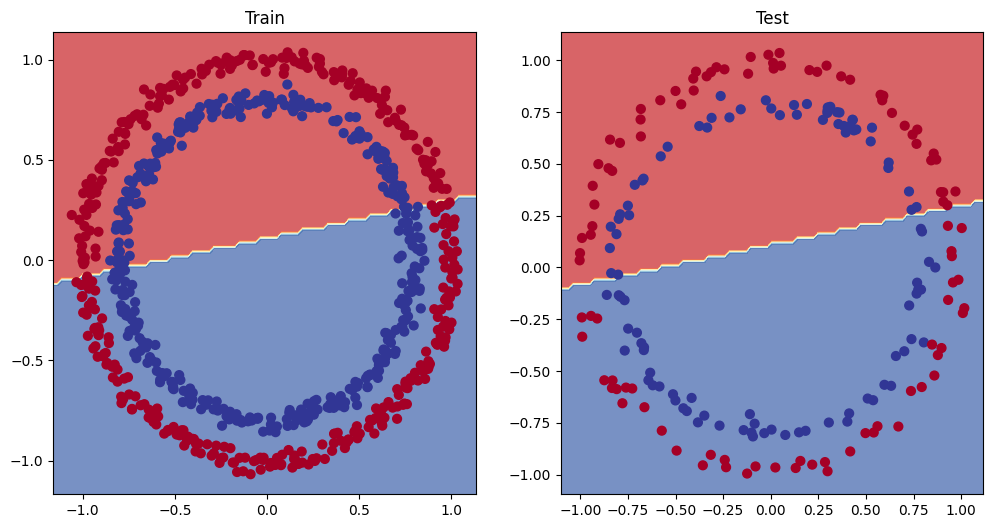

In [44]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 6))

ax1.set_title("Train")
plot_decision_boundary(model_1, X_train, y_train, ax=ax1)

ax2.set_title("Test")
plot_decision_boundary(model_1, X_test, y_test, ax=ax2)

plt.show()

### try to improve the model

In [45]:
#adding more hidden units and increase the number of layers

class CircleModelV1(nn.Module):
    def __init__(self):
     super().__init__()
     self.layer_1 = nn.Linear(in_features=2, out_features=10)
     self.layer_2 = nn.Linear(in_features=10, out_features=10)
     self.layer_3 = nn.Linear(in_features=10, out_features=1)
     
    def forward(self, X):
        return self.layer_3(self.layer_2(self.layer_1(X)))
    
model_2 = CircleModelV1()
model_2
    
    

CircleModelV1(
  (layer_1): Linear(in_features=2, out_features=10, bias=True)
  (layer_2): Linear(in_features=10, out_features=10, bias=True)
  (layer_3): Linear(in_features=10, out_features=1, bias=True)
)

In [46]:
model_1.state_dict()

OrderedDict([('0.weight',
              tensor([[-0.0849, -0.2762],
                      [ 0.4610, -0.5187],
                      [-0.3271, -0.1947],
                      [-0.4220,  0.0507],
                      [-0.7016,  0.6600]])),
             ('0.bias', tensor([-0.6060,  0.5246,  0.1149, -0.2211,  0.4275])),
             ('1.weight',
              tensor([[ 0.0741,  0.2406,  0.0222, -0.1075,  0.1965]])),
             ('1.bias', tensor([-0.1888]))])

In [47]:
model_2.state_dict()

OrderedDict([('layer_1.weight',
              tensor([[ 0.5406,  0.5869],
                      [-0.1657,  0.6496],
                      [-0.1549,  0.1427],
                      [-0.3443,  0.4153],
                      [ 0.6233, -0.5188],
                      [ 0.6146,  0.1323],
                      [ 0.5224,  0.0958],
                      [ 0.3410, -0.0998],
                      [ 0.5451,  0.1045],
                      [-0.3301,  0.1802]])),
             ('layer_1.bias',
              tensor([-0.3258, -0.0829, -0.2872,  0.4691, -0.5582, -0.3260, -0.1997, -0.4252,
                       0.0667, -0.6984])),
             ('layer_2.weight',
              tensor([[ 0.2856, -0.2686,  0.2441,  0.0526, -0.1027,  0.1954,  0.0493,  0.2555,
                        0.0346, -0.0997],
                      [ 0.0850, -0.0858,  0.1331,  0.2823,  0.1828, -0.1382,  0.1825,  0.0566,
                        0.1606, -0.1927],
                      [-0.3130, -0.1222, -0.2426,  0.2595,  0.0911,  0.1

In [48]:
loss_fn = nn.BCEWithLogitsLoss()

optimizer = torch.optim.SGD(params = model_2.parameters(),
                         lr = 0.1)

In [49]:
torch.manual_seed(42)

epochs = 1000 #increase the number of epochs to improve the model
for epoch in range(epochs):
    
    model_2.train()
    
    y_logits = model_2(X_train).squeeze()
    y_preds = torch.round(torch.sigmoid(y_logits))

    loss = loss_fn(y_logits, y_train)
    acc = accuracy(y_true=y_train, y_pred=y_preds)
    
    optimizer.zero_grad()
    
    loss.backward()
    optimizer.step()
    
    model_2.eval()
    with torch.inference_mode():
        test_logits = model_2(X_test).squeeze()
        test_preds = torch.round(torch.sigmoid(test_logits))
        
        test_loss = loss_fn(test_logits, y_test)
        test_acc = accuracy(y_test, test_preds)
        
    if epoch % 100 ==0 :
                print(f"Epoch: {epoch} | Loss: {loss:.5f} | Acc:{acc:.2f}% | Test Loss: {test_loss:.5f} | Test_Acc:{test_acc:.2f}%") 
        
    

Epoch: 0 | Loss: 0.69396 | Acc:50.88% | Test Loss: 0.69261 | Test_Acc:51.00%
Epoch: 100 | Loss: 0.69305 | Acc:50.38% | Test Loss: 0.69379 | Test_Acc:48.00%


Epoch: 200 | Loss: 0.69299 | Acc:51.12% | Test Loss: 0.69437 | Test_Acc:46.00%
Epoch: 300 | Loss: 0.69298 | Acc:51.62% | Test Loss: 0.69458 | Test_Acc:45.00%


Epoch: 400 | Loss: 0.69298 | Acc:51.12% | Test Loss: 0.69465 | Test_Acc:46.00%
Epoch: 500 | Loss: 0.69298 | Acc:51.00% | Test Loss: 0.69467 | Test_Acc:46.00%


Epoch: 600 | Loss: 0.69298 | Acc:51.00% | Test Loss: 0.69468 | Test_Acc:46.00%
Epoch: 700 | Loss: 0.69298 | Acc:51.00% | Test Loss: 0.69468 | Test_Acc:46.00%


Epoch: 800 | Loss: 0.69298 | Acc:51.00% | Test Loss: 0.69468 | Test_Acc:46.00%
Epoch: 900 | Loss: 0.69298 | Acc:51.00% | Test Loss: 0.69468 | Test_Acc:46.00%


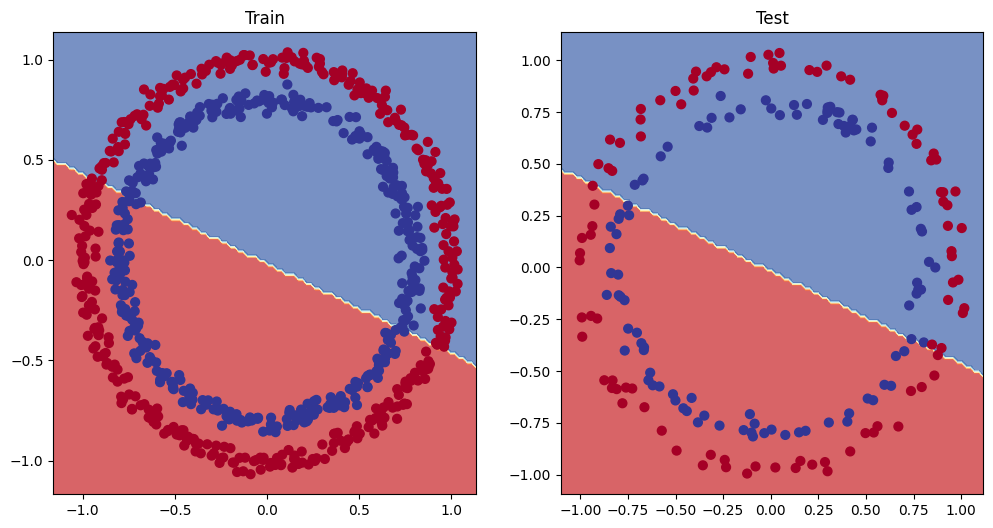

In [50]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 6))

ax1.set_title("Train")
plot_decision_boundary(model_2, X_train, y_train, ax=ax1)

ax2.set_title("Test")
plot_decision_boundary(model_2, X_test, y_test, ax=ax2)

plt.show()

### try with other data (linear data)

In [51]:
weight = 0.7
bias = 0.3

start = 0
stop = 1
step = 0.01

X_regression = torch.arange(start, stop, step).unsqueeze(dim=1)
y_regression = weight * X_regression + bias

print(len(X_regression))
X_regression[:5], y_regression[:5]


100


(tensor([[0.0000],
         [0.0100],
         [0.0200],
         [0.0300],
         [0.0400]]),
 tensor([[0.3000],
         [0.3070],
         [0.3140],
         [0.3210],
         [0.3280]]))

In [52]:
train_split = int(0.8 * len(X_regression))
X_train_regression, y_train_regression = X_regression[:train_split], y_regression[:train_split]
X_test_regression, y_test_regression = X_regression[train_split:], y_regression[train_split:]

len(X_train_regression), len(X_test_regression), len(y_train_regression), len(y_test_regression)

(80, 20, 80, 20)

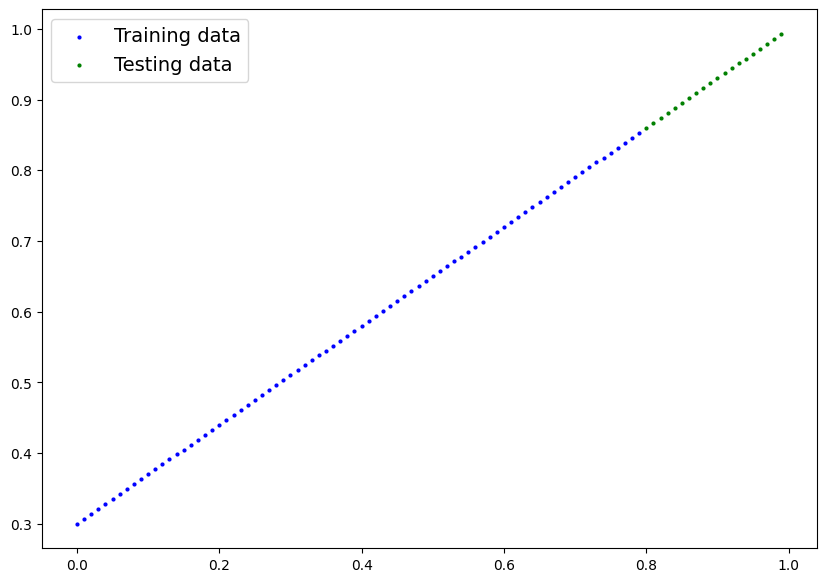

In [53]:
# visualize 
def plot_predictions(train_data=X_train_regression,
                     train_labels=y_train_regression,
                     test_data=X_test_regression,
                     test_labels=y_test_regression,
                     predictions=None):
    """
    Plots training data, test data and compares predictions.
    """

    plt.figure(figsize=(10, 7))

    # Plot training data in blue
    plt.scatter(train_data, train_labels, c="b", s=4, label="Training data")
    
    # Plot test data in green
    plt.scatter(test_data, test_labels, c="g", s=4, label="Testing data")

   # Are there predictions?
    if predictions is not None:
    # Plot the predictions if they exist
     plt.scatter(test_data, predictions, c="r", s=4, label="Predictions")

    # Show the legend
    plt.legend(prop={"size": 14})

plot_predictions()

In [54]:
model_2

CircleModelV1(
  (layer_1): Linear(in_features=2, out_features=10, bias=True)
  (layer_2): Linear(in_features=10, out_features=10, bias=True)
  (layer_3): Linear(in_features=10, out_features=1, bias=True)
)

### adjusting model_2 to fit straight line 

In [55]:
#same architecture as model_2 (by using nn.Sequential())
model_2 = nn.Sequential(
    nn.Linear(in_features=1, out_features=10),
    nn.Linear(in_features=10, out_features=10),
    nn.Linear(in_features=10, out_features=1)
)

model_2

Sequential(
  (0): Linear(in_features=1, out_features=10, bias=True)
  (1): Linear(in_features=10, out_features=10, bias=True)
  (2): Linear(in_features=10, out_features=1, bias=True)
)

In [56]:
loss_fn = torch.nn.L1Loss()
optimizer = torch.optim.SGD(params=model_2.parameters(),
                             lr=0.01)

In [57]:
torch.manual_seed(42)

epochs = 1000

for epoch in range(epochs):
    model_2.train()
    y_pred = model_2(X_train_regression)
    loss = loss_fn(y_pred, y_train_regression)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    
    model_2.eval()
    with torch.inference_mode():
        test_pred = model_2(X_test_regression)
        test_loss = loss_fn(test_pred, y_test_regression)
        
    if epoch % 100 == 0:
        print(f"Epoch:{epoch} | loss:{loss:.5f} | test_loss:{test_loss:.5f}")

Epoch:0 | loss:0.75986 | test_loss:0.91103
Epoch:100 | loss:0.02858 | test_loss:0.00081
Epoch:200 | loss:0.02533 | test_loss:0.00209


Epoch:300 | loss:0.02137 | test_loss:0.00305
Epoch:400 | loss:0.01964 | test_loss:0.00341
Epoch:500 | loss:0.01940 | test_loss:0.00387


Epoch:600 | loss:0.01903 | test_loss:0.00379
Epoch:700 | loss:0.01878 | test_loss:0.00381
Epoch:800 | loss:0.01840 | test_loss:0.00329


Epoch:900 | loss:0.01798 | test_loss:0.00360


In [58]:
# make some prediction
model_2.eval()
with torch.inference_mode():
    y_pred_new = model_2(X_test_regression)
y_pred_new

tensor([[0.8246],
        [0.8312],
        [0.8377],
        [0.8443],
        [0.8509],
        [0.8574],
        [0.8640],
        [0.8706],
        [0.8771],
        [0.8837],
        [0.8903],
        [0.8968],
        [0.9034],
        [0.9100],
        [0.9165],
        [0.9231],
        [0.9297],
        [0.9362],
        [0.9428],
        [0.9494]])

In [59]:
y_test_regression

tensor([[0.8600],
        [0.8670],
        [0.8740],
        [0.8810],
        [0.8880],
        [0.8950],
        [0.9020],
        [0.9090],
        [0.9160],
        [0.9230],
        [0.9300],
        [0.9370],
        [0.9440],
        [0.9510],
        [0.9580],
        [0.9650],
        [0.9720],
        [0.9790],
        [0.9860],
        [0.9930]])

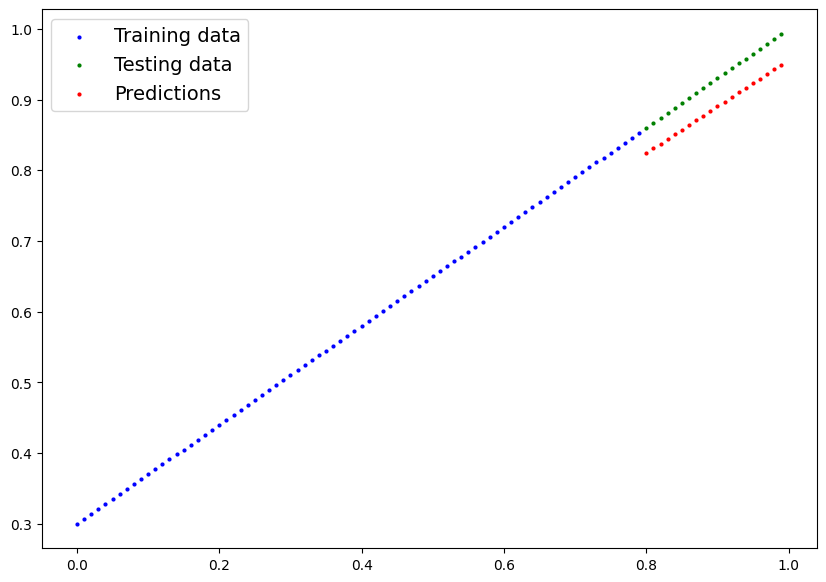

In [60]:
plot_predictions(predictions=y_pred_new)

In [61]:
# (الفكرة انو المودل تبعنا شغال وكويس وقابل للتعلم على داتا خطية بس ما قدر يتعامل مع ال غير خطية (الدائرية مثلاً 

### Non_Linearity 

In [62]:
from sklearn.datasets import make_circles

n_samples = 1000

X, y = make_circles(n_samples,
                    noise=0.03,
                    random_state=True)

In [63]:
X[:5], y[:5]

(array([[ 0.83619806,  0.03563148],
        [-0.53059757, -0.6487148 ],
        [ 0.85386881, -0.61156583],
        [-0.09214707, -0.9651441 ],
        [-1.00162344,  0.14446653]]),
 array([1, 1, 0, 0, 0]))

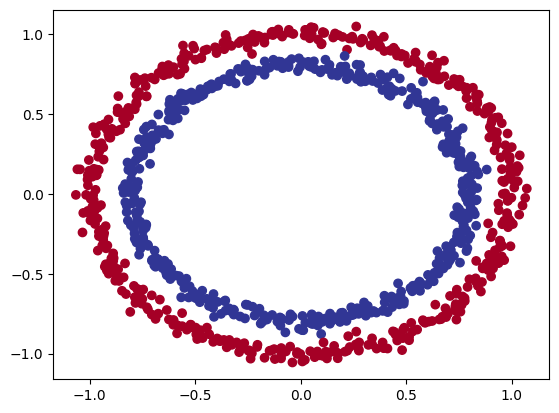

In [64]:
import matplotlib.pyplot as plt
plt.scatter(X[:, 0], X[:, 1], c=y, cmap=plt.cm.RdYlBu)

In [65]:
X = torch.from_numpy(X).type(torch.float)
y = torch.from_numpy(y).type(torch.float)

In [66]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=True)
type(X_train), X_train

(torch.Tensor,
 tensor([[-0.4046,  0.6731],
         [ 0.3087, -0.7629],
         [-0.9086, -0.4370],
         ...,
         [ 0.0793, -0.9867],
         [ 0.5317, -0.5755],
         [-0.7125,  0.2839]]))

In [67]:
class CircleModelV2(nn.Module):
    def __init__(self):
        super().__init__()
        self.layer_1 = nn.Linear(in_features=2, out_features=10)
        self.layer_2 = nn.Linear(in_features=10, out_features=10)
        self.layer_3 = nn.Linear(in_features=10, out_features=1)
        self.relu = nn.ReLU() #non linear activation function
        
    def forward(self, X):
        return self.layer_3(self.relu(self.layer_2(self.relu(self.layer_1(X)))))
    
model_3 = CircleModelV2()
model_3
    

CircleModelV2(
  (layer_1): Linear(in_features=2, out_features=10, bias=True)
  (layer_2): Linear(in_features=10, out_features=10, bias=True)
  (layer_3): Linear(in_features=10, out_features=1, bias=True)
  (relu): ReLU()
)

In [68]:
loss_fn = nn.BCEWithLogitsLoss()
optimizer = torch.optim.SGD(params=model_3.parameters(),
                            lr=0.1)

In [69]:
torch.manual_seed(42)

epochs = 1000

for epoch in range(epochs):
    model_3.train()
    y_logits = model_3(X_train).squeeze()
    y_pred = torch.round(torch.sigmoid(y_logits))
    
    loss = loss_fn(y_logits, y_train)
    acc = accuracy(y_train, y_pred)
    
    optimizer.zero_grad()
    
    loss.backward()
    optimizer.step()
    
    model_3.eval()
    with torch.inference_mode():
        test_logits = model_3(X_test).squeeze()
        test_pred = torch.round(torch.sigmoid(test_logits))
        
        test_loss = loss_fn(test_logits, y_test)
        test_acc = accuracy(y_test, test_pred)
        
    if epoch % 100 == 0 :
        
     print(f"epoch:{epoch} | loss:{loss:.4f} | accuracy:{acc:.2f} | test loss:{test_loss:.4f} | test accuracy:{test_acc:.2f}")

epoch:0 | loss:0.6931 | accuracy:49.62 | test loss:0.6923 | test accuracy:51.50
epoch:100 | loss:0.6909 | accuracy:51.75 | test loss:0.6913 | test accuracy:53.50


epoch:200 | loss:0.6891 | accuracy:52.75 | test loss:0.6899 | test accuracy:53.00
epoch:300 | loss:0.6865 | accuracy:54.25 | test loss:0.6880 | test accuracy:53.00


epoch:400 | loss:0.6831 | accuracy:54.37 | test loss:0.6853 | test accuracy:52.50
epoch:500 | loss:0.6783 | accuracy:55.00 | test loss:0.6812 | test accuracy:52.50
epoch:600 | loss:0.6710 | accuracy:55.12 | test loss:0.6745 | test accuracy:53.00


epoch:700 | loss:0.6599 | accuracy:56.38 | test loss:0.6646 | test accuracy:55.50
epoch:800 | loss:0.6429 | accuracy:63.88 | test loss:0.6478 | test accuracy:61.50
epoch:900 | loss:0.6143 | accuracy:73.88 | test loss:0.6205 | test accuracy:70.00


In [70]:
model_3.state_dict()

OrderedDict([('layer_1.weight',
              tensor([[ 0.6982,  0.8192],
                      [-0.2946,  0.7684],
                      [-0.1549,  0.1427],
                      [-0.9183,  0.4021],
                      [ 0.5683, -1.3513],
                      [ 0.6664,  0.2050],
                      [ 0.8755,  0.2384],
                      [ 0.3410, -0.0998],
                      [ 0.6630,  0.2798],
                      [-0.3301,  0.1802]])),
             ('layer_1.bias',
              tensor([-0.4671, -0.2455, -0.2872,  0.2173, -0.4507, -0.3536, -0.4174, -0.4252,
                      -0.2660, -0.6984])),
             ('layer_2.weight',
              tensor([[ 1.2831e-01, -3.8946e-01,  2.4414e-01, -5.0436e-02, -2.7373e-01,
                        1.0126e-01, -5.9913e-02,  2.5550e-01, -5.1234e-02, -9.9730e-02],
                      [ 8.4011e-01,  4.8294e-01,  1.3309e-01,  7.6435e-01,  1.0148e+00,
                        3.1265e-01,  7.1121e-01,  5.6581e-02,  5.6353e-01, -1.927

In [71]:
model_3.eval()
with torch.inference_mode():
    y_preds = torch.round(torch.sigmoid(model_3(X_test))).squeeze()
y_preds[:10], y_test[:10]

(tensor([1., 1., 0., 0., 1., 1., 0., 0., 1., 1.]),
 tensor([1., 1., 1., 0., 0., 0., 0., 0., 0., 1.]))

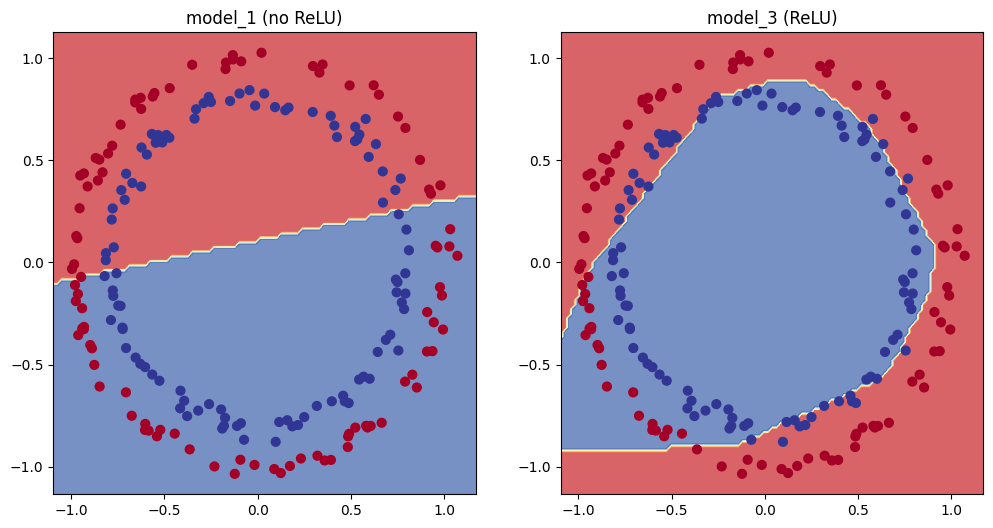

In [72]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 6))

ax1.set_title("model_1 (no ReLU)")
plot_decision_boundary(model_1, X_test, y_test, ax=ax1) #no non-linearity 

ax2.set_title("model_3 (ReLU)")
plot_decision_boundary(model_3, X_test, y_test, ax=ax2) # has non-linearity

plt.show() # في تحسن كثير عن المودل الاول وممكن يتحسن اكثر

### another example

In [73]:
A = torch.arange(-10, 10, 1, dtype =torch.float32)
A

tensor([-10.,  -9.,  -8.,  -7.,  -6.,  -5.,  -4.,  -3.,  -2.,  -1.,   0.,   1.,
          2.,   3.,   4.,   5.,   6.,   7.,   8.,   9.])

In [74]:
A.dtype

torch.float32

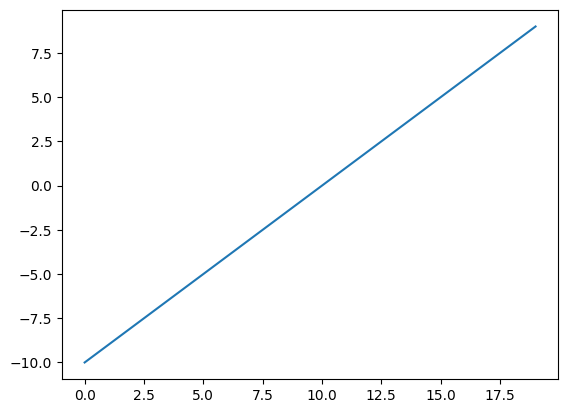

In [75]:
plt.plot(A)

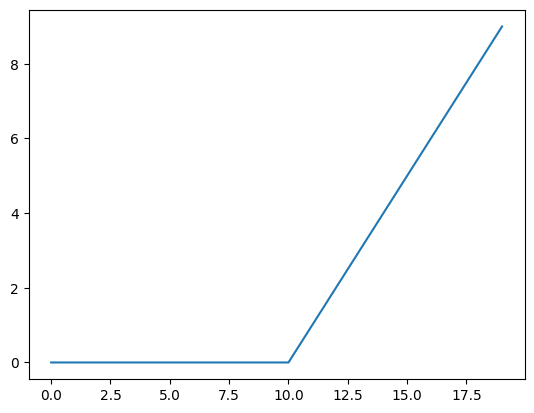

In [76]:
plt.plot(torch.relu(A))

In [77]:
def relu(x: torch.Tensor) -> torch.Tensor:
    return torch.maximum(torch.tensor(0),x)

relu(A)

tensor([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 1., 2., 3., 4., 5., 6., 7.,
        8., 9.])

In [78]:
A

tensor([-10.,  -9.,  -8.,  -7.,  -6.,  -5.,  -4.,  -3.,  -2.,  -1.,   0.,   1.,
          2.,   3.,   4.,   5.,   6.,   7.,   8.,   9.])

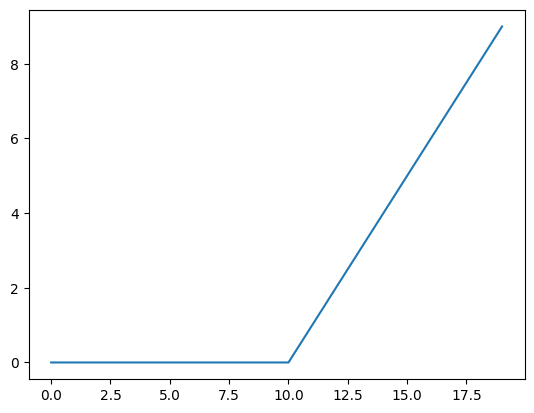

In [79]:
plt.plot(relu(A))

In [80]:
torch.sigmoid(A)

tensor([4.5398e-05, 1.2339e-04, 3.3535e-04, 9.1105e-04, 2.4726e-03, 6.6929e-03,
        1.7986e-02, 4.7426e-02, 1.1920e-01, 2.6894e-01, 5.0000e-01, 7.3106e-01,
        8.8080e-01, 9.5257e-01, 9.8201e-01, 9.9331e-01, 9.9753e-01, 9.9909e-01,
        9.9966e-01, 9.9988e-01])

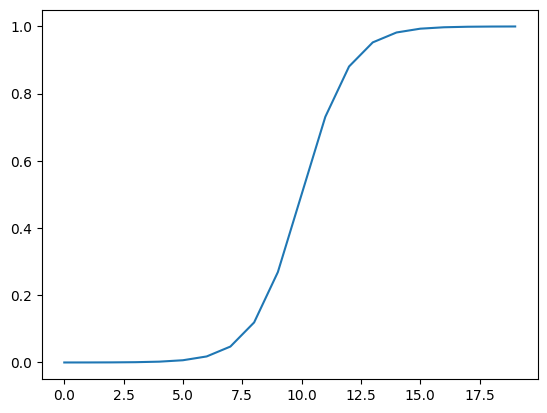

In [81]:
plt.plot(torch.sigmoid(A))

In [82]:
def sigmoid(x):
    return 1 / (1 + torch.exp(-x))

In [83]:
sigmoid(A)

tensor([4.5398e-05, 1.2339e-04, 3.3535e-04, 9.1105e-04, 2.4726e-03, 6.6929e-03,
        1.7986e-02, 4.7426e-02, 1.1920e-01, 2.6894e-01, 5.0000e-01, 7.3106e-01,
        8.8080e-01, 9.5257e-01, 9.8201e-01, 9.9331e-01, 9.9753e-01, 9.9909e-01,
        9.9966e-01, 9.9988e-01])

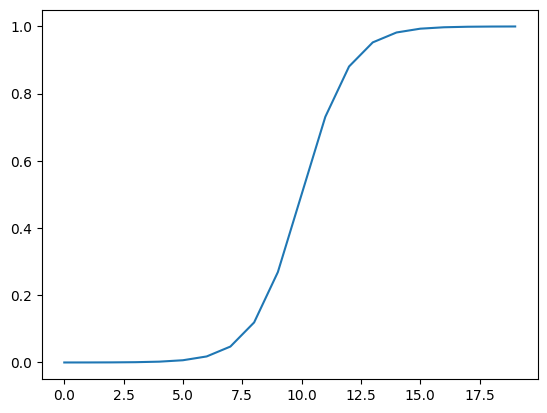

In [84]:
plt.plot(sigmoid(A))

### MultiClass Classification

In [85]:
from sklearn.datasets import make_blobs

NUM_FEATURES = 2
NUM_CLASSES = 4
RANDOM_SEED = 42

X_blob, y_blob = make_blobs(n_samples=1000,
                            n_features=NUM_FEATURES,
                            centers=NUM_CLASSES,
                            cluster_std=1.5,
                            random_state=RANDOM_SEED)

In [86]:
X_blob[:10], y_blob[:10]

(array([[-8.41339595,  6.93516545],
        [-5.76648413, -6.43117072],
        [-6.04213682, -6.76610151],
        [ 3.95083749,  0.69840313],
        [ 4.25049181, -0.28154475],
        [-6.7941075 , -6.47722117],
        [ 5.21017561,  2.8890483 ],
        [-5.50513568, -6.36037688],
        [-6.54375599, -4.83389895],
        [ 6.44964229,  0.74776618]]),
 array([3, 2, 2, 1, 1, 2, 1, 2, 2, 1]))

In [87]:
import pandas as pd
blobs = pd.DataFrame({"X1" : X_blob[:, 0],
                        "X2" : X_blob[:, 1],
                        "label" : y_blob})

blobs

,X1,X2,label
0,-8.413396,6.935165,3
1,-5.766484,-6.431171,2
2,-6.042137,-6.766102,2
3,3.950837,0.698403,1
4,4.250492,-0.281545,1
...,...,...,...
995,-3.787372,-5.067560,2
996,-1.573018,9.956804,0
997,3.215781,5.921743,1
998,-7.793895,-7.160567,2


In [88]:
X_blob = torch.from_numpy(X_blob).type(torch.float)
y_blob = torch.from_numpy(y_blob).type(torch.LongTensor)

In [89]:
from sklearn.model_selection import train_test_split
X_blob_train, X_blob_test, y_blob_train, y_blob_test = train_test_split(X_blob, y_blob, test_size=0.2, random_state=True)

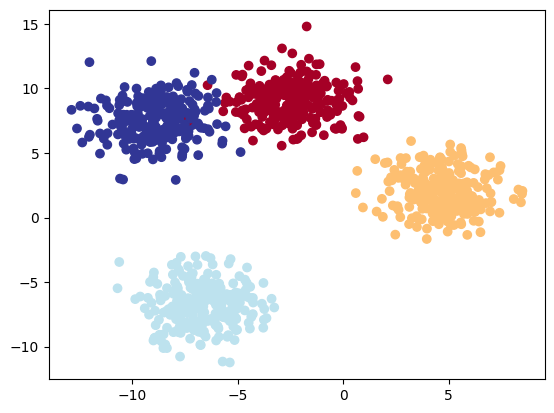

In [90]:
plt.scatter(X_blob[:,0], X_blob[:,1], c=y_blob, cmap=plt.cm.RdYlBu)

In [91]:
#building a multi-class classification model in pytorch

class BlobModel(nn.Module):
    def __init__(self, input_features, output_features, hidden_units=8):
        super().__init__()
        self.linear_layer_stack = nn.Sequential(
            nn.Linear(in_features=input_features, out_features=hidden_units),
            #nn.ReLU(),
            nn.Linear(in_features=hidden_units, out_features=hidden_units),
            #nn.ReLU(),
            nn.Linear(in_features=hidden_units, out_features=output_features)
        )
        
    def forward(self, x):
        return self.linear_layer_stack(x)
    
model_4 = BlobModel(input_features=2,
                    output_features=4,
                    hidden_units=8)
model_4
        

BlobModel(
  (linear_layer_stack): Sequential(
    (0): Linear(in_features=2, out_features=8, bias=True)
    (1): Linear(in_features=8, out_features=8, bias=True)
    (2): Linear(in_features=8, out_features=4, bias=True)
  )
)

In [92]:
X_blob_train.shape, y_blob_train.shape

(torch.Size([800, 2]), torch.Size([800]))

In [93]:
X_blob_test.shape, y_blob_test.shape

(torch.Size([200, 2]), torch.Size([200]))

In [94]:
torch.unique(y_blob_train) #4 classes

tensor([0, 1, 2, 3])

In [95]:
loss_fn = nn.CrossEntropyLoss()

In [96]:
optimizer = torch.optim.SGD(params=model_4.parameters(),
                            lr=0.1)

In [97]:
model_4.eval()
with torch.inference_mode():
    y_logits = model_4(X_blob_test)
y_logits[:10] #this is logits and not the same format as y_blob_test

tensor([[-0.7816, -0.8414, -0.9621, -0.1714],
        [ 2.6284,  0.6270,  3.0093,  1.4276],
        [-1.6270, -0.3516, -1.8234, -1.2110],
        [ 1.4956, -1.2854,  1.4844,  1.9695],
        [ 2.0902,  0.7554,  2.4344,  0.9040],
        [-0.6300, -0.1162, -0.6903, -0.5974],
        [ 2.2222, -0.9758,  2.3302,  2.3127],
        [ 0.4206, -1.4419,  0.2768,  1.2346],
        [ 2.0784, -1.2767,  2.1283,  2.4253],
        [-0.9005, -0.1376, -0.9915, -0.7958]])

In [98]:
y_blob_test[:10]

tensor([1, 2, 1, 3, 2, 1, 3, 0, 3, 1])

logits -> pred probs -> pred labels

In [99]:
# we use activation function to turn logits to prediction probabilities

y_pred_probs = torch.softmax(y_logits, dim=1)
y_pred_probs[:10], y_logits[:10]



(tensor([[0.2166, 0.2040, 0.1808, 0.3986],
         [0.3449, 0.0466, 0.5047, 0.1038],
         [0.1446, 0.5175, 0.1188, 0.2191],
         [0.2734, 0.0169, 0.2704, 0.4392],
         [0.3356, 0.0883, 0.4736, 0.1025],
         [0.2152, 0.3598, 0.2026, 0.2224],
         [0.3077, 0.0126, 0.3428, 0.3369],
         [0.2337, 0.0363, 0.2024, 0.5275],
         [0.2857, 0.0100, 0.3003, 0.4041],
         [0.1935, 0.4150, 0.1767, 0.2149]]),
 tensor([[-0.7816, -0.8414, -0.9621, -0.1714],
         [ 2.6284,  0.6270,  3.0093,  1.4276],
         [-1.6270, -0.3516, -1.8234, -1.2110],
         [ 1.4956, -1.2854,  1.4844,  1.9695],
         [ 2.0902,  0.7554,  2.4344,  0.9040],
         [-0.6300, -0.1162, -0.6903, -0.5974],
         [ 2.2222, -0.9758,  2.3302,  2.3127],
         [ 0.4206, -1.4419,  0.2768,  1.2346],
         [ 2.0784, -1.2767,  2.1283,  2.4253],
         [-0.9005, -0.1376, -0.9915, -0.7958]]))

In [100]:
y_pred_probs[0]

tensor([0.2166, 0.2040, 0.1808, 0.3986])

In [101]:
torch.sum(y_pred_probs[1]) #دائما مجموعهم يساوي ١

tensor(1.)

In [102]:
torch.max(y_pred_probs[0]) #0.3986 هو نسبة ان المودل يعتقد انو هذه العينة تنتمي ل كلاس ٣ 

tensor(0.3986)

In [103]:
torch.argmax(y_pred_probs[2])  

tensor(1)

In [104]:
#turn the probabilities into a label
y_preds = torch.argmax(y_pred_probs, dim=1)
y_preds

tensor([3, 2, 1, 3, 2, 1, 2, 3, 3, 1, 3, 3, 3, 1, 2, 3, 3, 1, 3, 2, 3, 1, 3, 3,
        3, 1, 2, 2, 3, 3, 3, 3, 2, 3, 1, 3, 3, 2, 3, 3, 1, 1, 3, 3, 3, 3, 1, 2,
        3, 2, 3, 3, 1, 3, 3, 3, 1, 1, 1, 1, 1, 2, 3, 2, 3, 1, 3, 2, 1, 3, 2, 1,
        2, 2, 2, 3, 3, 2, 2, 3, 2, 3, 3, 2, 3, 1, 3, 2, 2, 2, 1, 2, 3, 3, 3, 2,
        3, 3, 2, 3, 3, 2, 1, 3, 1, 3, 1, 1, 3, 2, 3, 3, 2, 2, 3, 3, 3, 3, 3, 3,
        3, 3, 1, 3, 2, 1, 3, 3, 2, 3, 3, 1, 3, 2, 3, 3, 3, 3, 3, 3, 2, 3, 3, 3,
        2, 1, 2, 3, 1, 3, 3, 3, 2, 3, 3, 3, 3, 2, 1, 2, 3, 3, 2, 3, 3, 3, 3, 2,
        3, 3, 3, 3, 1, 1, 1, 2, 1, 3, 3, 3, 2, 2, 1, 3, 3, 2, 3, 3, 2, 2, 3, 2,
        3, 3, 2, 3, 2, 3, 3, 3])

In [105]:
y_blob_test

tensor([1, 2, 1, 3, 2, 1, 3, 0, 3, 1, 1, 3, 3, 1, 2, 3, 3, 1, 1, 2, 1, 1, 0, 3,
        0, 1, 2, 2, 3, 0, 0, 3, 2, 0, 1, 0, 1, 2, 3, 3, 1, 1, 0, 3, 3, 3, 1, 2,
        0, 2, 0, 0, 1, 3, 0, 0, 1, 1, 1, 1, 1, 2, 3, 2, 3, 1, 1, 2, 1, 0, 2, 1,
        3, 2, 2, 0, 0, 2, 2, 3, 2, 3, 3, 2, 0, 1, 0, 2, 2, 2, 1, 2, 0, 1, 3, 2,
        0, 0, 2, 0, 0, 2, 1, 0, 1, 0, 1, 1, 3, 2, 0, 0, 2, 2, 3, 3, 3, 3, 0, 0,
        1, 3, 1, 0, 2, 1, 3, 0, 2, 0, 0, 1, 0, 2, 1, 0, 0, 3, 0, 3, 2, 3, 0, 0,
        2, 1, 2, 0, 1, 0, 0, 0, 2, 3, 0, 3, 3, 2, 1, 2, 3, 1, 2, 0, 0, 3, 3, 2,
        3, 3, 1, 0, 1, 1, 1, 2, 1, 3, 3, 1, 2, 2, 1, 3, 1, 2, 0, 0, 2, 2, 3, 2,
        3, 3, 2, 0, 2, 3, 3, 0])

In [106]:
#build Multi-Class model
torch.manual_seed(42)

epochs = 100

for epoch in range(epochs):
    model_4.train()
    y_logits = model_4(X_blob_train).squeeze()
    y_preds = torch.softmax(y_logits, dim=1).argmax(dim=1)
    
    loss = loss_fn(y_logits, y_blob_train)
    acc = accuracy(y_blob_train, y_preds)
    optimizer.zero_grad()
    
    loss.backward()
    optimizer.step()
    
    model_4.eval()
    with torch.inference_mode():
        test_logits = model_4(X_blob_test).squeeze()
        test_pred = torch.softmax(test_logits, dim=1).argmax(dim=1)
        
        test_loss = loss_fn(test_logits, y_blob_test)
        test_acc = accuracy(y_blob_test, test_pred)
    
    if epoch % 10 == 0 :
            
         print(f"epoch:{epoch} | loss:{loss:.4f} | accuracy:{acc:.2f} | test loss:{test_loss:.4f} | test accuracy:{test_acc:.2f}%")

epoch:0 | loss:1.0410 | accuracy:65.75 | test loss:0.5691 | test accuracy:97.50%
epoch:10 | loss:0.1448 | accuracy:99.12 | test loss:0.1277 | test accuracy:98.50%
epoch:20 | loss:0.0808 | accuracy:99.38 | test loss:0.0707 | test accuracy:98.50%
epoch:30 | loss:0.0592 | accuracy:99.38 | test loss:0.0505 | test accuracy:98.50%
epoch:40 | loss:0.0488 | accuracy:99.38 | test loss:0.0405 | test accuracy:98.50%
epoch:50 | loss:0.0428 | accuracy:99.38 | test loss:0.0347 | test accuracy:98.50%
epoch:60 | loss:0.0388 | accuracy:99.38 | test loss:0.0309 | test accuracy:98.50%
epoch:70 | loss:0.0361 | accuracy:99.38 | test loss:0.0283 | test accuracy:98.50%
epoch:80 | loss:0.0341 | accuracy:99.38 | test loss:0.0264 | test accuracy:98.50%
epoch:90 | loss:0.0326 | accuracy:99.38 | test loss:0.0249 | test accuracy:99.00%


In [107]:
model_4.eval()
with torch.inference_mode():
    y_logits = model_4(X_blob_test)
y_logits[:10]

tensor([[  4.3003,   6.8755, -11.8268,  -6.5698],
        [ -5.1275, -16.5191,  22.9630,  15.6293],
        [  2.2168,  13.7295, -14.4714, -12.6811],
        [  5.3799, -10.5066,   1.4289,   9.2694],
        [ -5.5042, -12.3819,  19.9944,  11.8690],
        [  0.4645,   6.6502,  -5.6581,  -6.0527],
        [  3.3883, -15.4954,   8.8184,  14.0018],
        [  6.7655,  -2.7537,  -7.3920,   2.0535],
        [  5.0231, -14.8043,   5.6780,  13.2362],
        [  0.7201,   8.6229,  -7.7516,  -7.8809]])

In [108]:
y_preds_prob = torch.softmax(y_logits, dim=1)
y_preds_prob[:10]

tensor([[7.0753e-02, 9.2925e-01, 7.0118e-09, 1.3456e-06],
        [6.3120e-13, 7.1262e-18, 9.9935e-01, 6.5271e-04],
        [1.0003e-05, 9.9999e-01, 5.6560e-13, 3.3886e-12],
        [2.0038e-02, 2.5259e-09, 3.8545e-04, 9.7958e-01],
        [8.4327e-12, 8.6899e-15, 9.9970e-01, 2.9583e-04],
        [2.0545e-03, 9.9794e-01, 4.5049e-06, 3.0362e-06],
        [2.4445e-05, 1.5385e-13, 5.5778e-03, 9.9440e-01],
        [9.9102e-01, 7.2767e-05, 7.0398e-07, 8.9055e-03],
        [2.7088e-04, 6.6346e-13, 5.2142e-04, 9.9921e-01],
        [3.6959e-04, 9.9963e-01, 7.7357e-08, 6.7973e-08]])

In [109]:
y_preds = torch.argmax(y_preds_prob, dim=1)
y_preds[:10]

tensor([1, 2, 1, 3, 2, 1, 3, 0, 3, 1])

In [110]:
y_blob_test[:10]

tensor([1, 2, 1, 3, 2, 1, 3, 0, 3, 1])

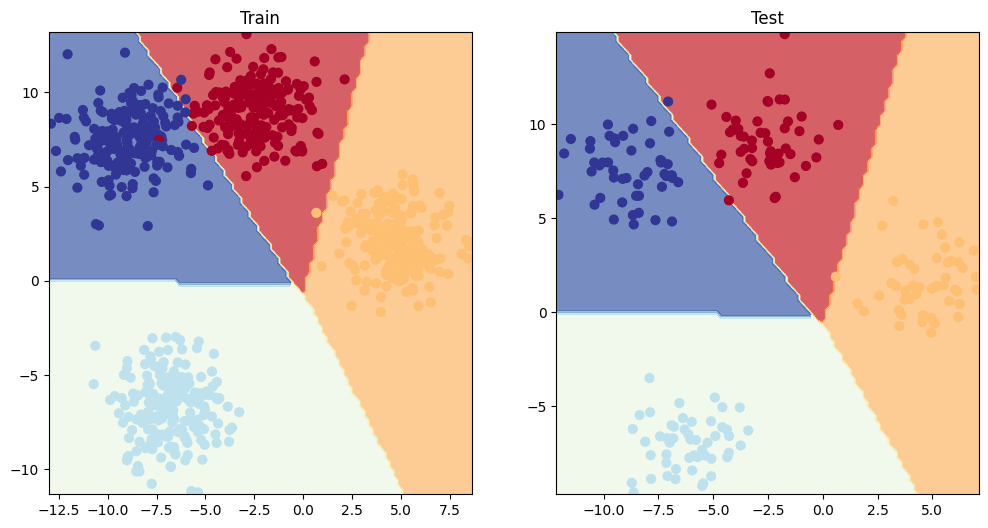

In [111]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 6))

ax1.set_title("Train")
plot_decision_boundary(model_4, X_blob_train, y_blob_train, ax=ax1)

ax2.set_title("Test")
plot_decision_boundary(model_4, X_blob_test, y_blob_test, ax=ax2)

plt.show()

In [112]:
from torchmetrics import Accuracy
torchmetrics_accuracy = Accuracy(task="multiclass", num_classes=4)
torchmetrics_accuracy(y_preds, y_blob_test)

tensor(0.9900)